In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
###Load Datasets
apps=pd.read_csv('/content/googleplaystore.csv')
reviews = pd.read_csv('/content/googleplaystore_user_reviews.csv')

In [4]:
print("Google Play Store Apps Dataset:")
display(apps.head())
print("Google Play Store Reviews Dataset:")
display(reviews.head())

Google Play Store Apps Dataset:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


Google Play Store Reviews Dataset:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [5]:
print("Apps Dataset:")
apps.info()
print("\nReviews Dataset:")
reviews.info()

Apps Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

Reviews Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column            

In [6]:
# Check Missing Values
print("Missing Values in Apps Dataset:")
print(apps.isnull().sum())
print("\nMissing Values in Reviews Dataset:")
print(reviews.isnull().sum())

Missing Values in Apps Dataset:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Missing Values in Reviews Dataset:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


In [7]:
###Handle Missing Values and drop duplicates
apps.dropna(subset=['Rating'], inplace=True)
apps['Type'] = apps['Type'].fillna(apps['Type'].mode()[0])
apps['Content Rating'] = apps['Content Rating'].fillna(apps['Content Rating'].mode()[0])
apps['Current Ver'] = apps['Current Ver'].fillna(apps['Current Ver'].mode()[0])
apps['Android Ver'] = apps['Android Ver'].fillna(apps['Android Ver'].mode()[0])
reviews.dropna(subset=['Translated_Review', 'Sentiment'], inplace=True)
apps.drop_duplicates(inplace=True)
reviews.drop_duplicates(inplace=True)

In [8]:
print(apps[['Installs', 'Price']].dtypes)

Installs    object
Price       object
dtype: object


In [9]:
# Check and View Duplicate Apps
print("Duplicate apps:", apps['App'].duplicated().sum())
duplicate_apps = apps[apps['App'].duplicated(keep=False)].sort_values('App')
display(duplicate_apps.head(10))

Duplicate apps: 696


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
5415,365Scores - Live Scores,SPORTS,4.6,666246,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
3083,365Scores - Live Scores,SPORTS,4.6,666521,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
3953,8 Ball Pool,SPORTS,4.5,14184910,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1970,8 Ball Pool,GAME,4.5,14201604,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1675,8 Ball Pool,GAME,4.5,14198297,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1755,8 Ball Pool,GAME,4.5,14200344,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1871,8 Ball Pool,GAME,4.5,14201891,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1844,8 Ball Pool,GAME,4.5,14200550,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1703,8 Ball Pool,GAME,4.5,14198602,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
559,95Live -SG#1 Live Streaming App,DATING,4.1,4953,15M,"1,000,000+",Free,0,Teen,Dating,"August 1, 2018",8.7.2,4.2 and up


In [10]:
# Remove Duplicate Apps
apps = apps.sort_values('Reviews', ascending=False)
apps.drop_duplicates(subset='App', keep='first', inplace=True)
apps.reset_index(drop=True, inplace=True)
print("Remaining duplicate apps:", apps['App'].duplicated().sum())
print("Total apps after cleaning:", apps.shape[0])

Remaining duplicate apps: 0
Total apps after cleaning: 8197


In [11]:
print("Apps Dataset:")
print(apps.isnull().sum())
print("\nData Types:")
print(apps.dtypes)
print("\nReviews Dataset:")
print(reviews.isnull().sum())

Apps Dataset:
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

Data Types:
App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

Reviews Dataset:
App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64


In [13]:
apps[apps['Reviews'].astype(str).str.contains('M', na=False)]
apps = apps[apps['Installs'] != 'Free']
apps['Installs'] = apps['Installs'].str.replace(',', '').str.replace('+', '').astype(int)
apps['Price'] = apps['Price'].str.replace('$', '', regex=False).astype(float)
apps['Size'] = apps['Size'].str.replace('M', '', regex=False)
apps['Size'] = pd.to_numeric(apps['Size'], errors='coerce')

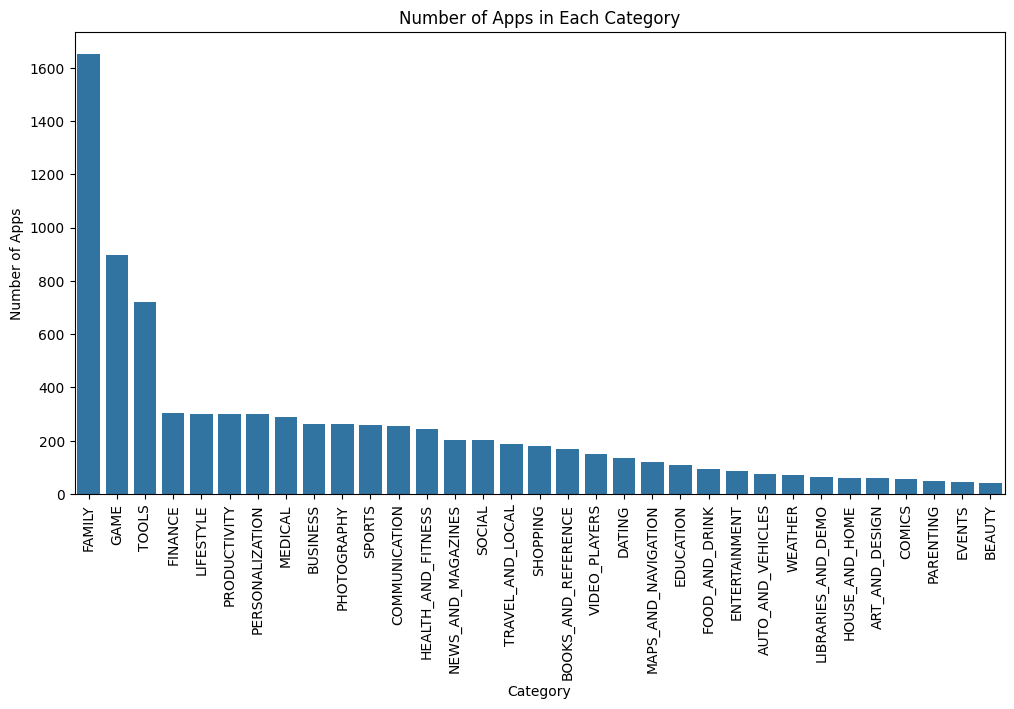

In [14]:
###Category Analysis
category_counts = apps['Category'].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.index, y=category_counts.values)
plt.xticks(rotation=90)
plt.title('Number of Apps in Each Category')
plt.xlabel('Category')
plt.ylabel('Number of Apps')
plt.show()

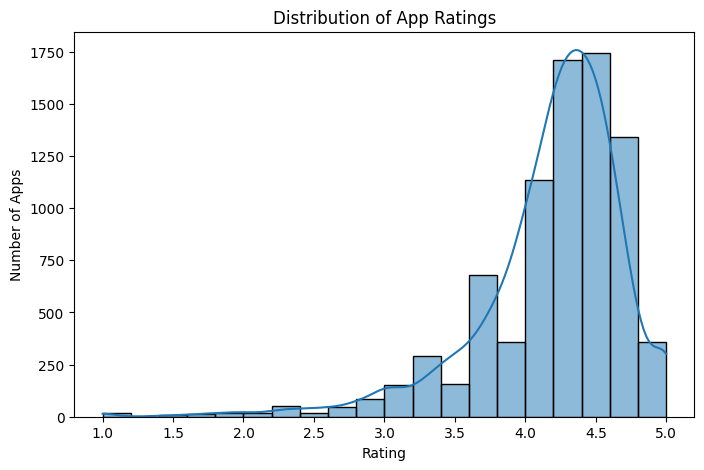

In [15]:
### Distribution of App Ratings
plt.figure(figsize=(8, 5))
sns.histplot(apps['Rating'], bins=20, kde=True)
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')
plt.show()

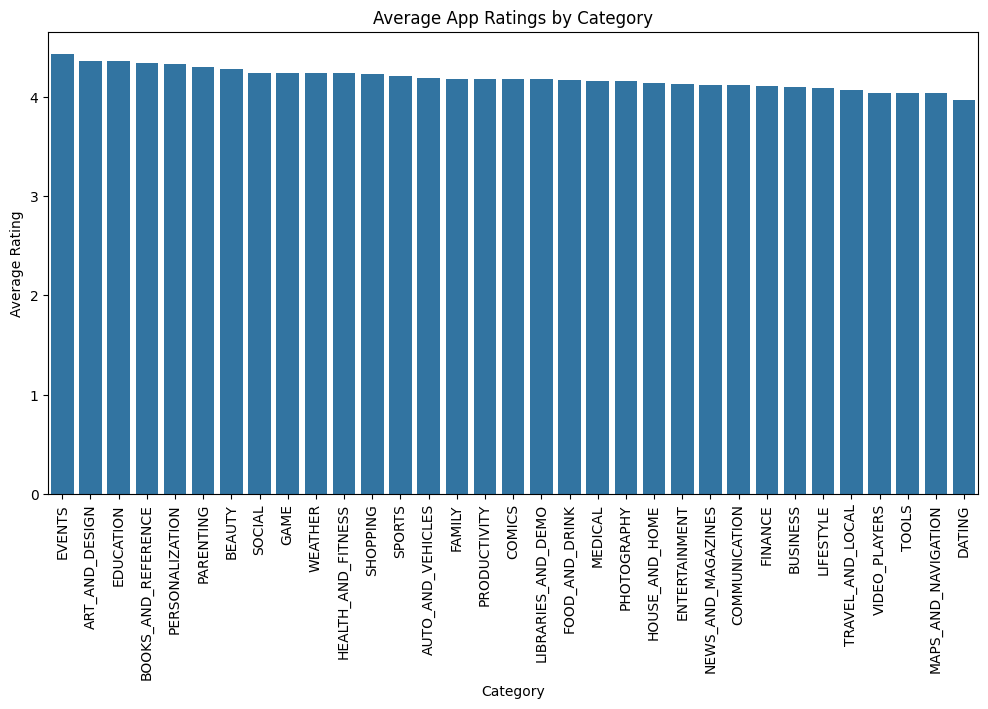

In [16]:
### Average Ratings by Category
avg_ratings = apps.groupby('Category')['Rating'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_ratings.index, y=avg_ratings.values)
plt.xticks(rotation=90)
plt.title('Average App Ratings by Category')
plt.xlabel('Category')
plt.ylabel('Average Rating')
plt.show()

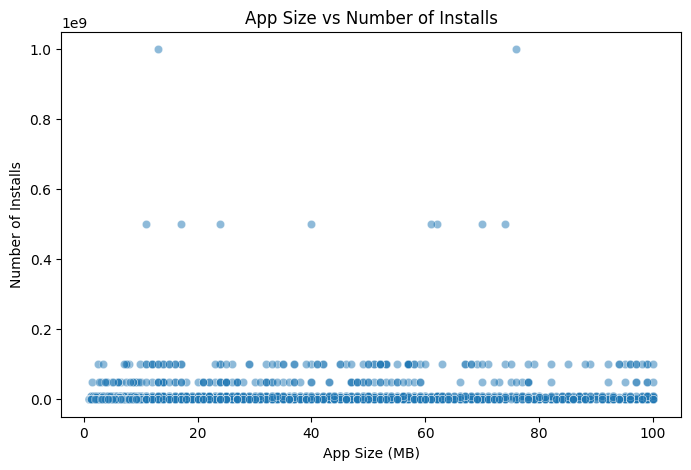

In [17]:
### App Size vs Number of Installs
plt.figure(figsize=(8, 5))
sns.scatterplot(data=apps, x='Size', y='Installs', alpha=0.5)
plt.title('App Size vs Number of Installs')
plt.xlabel('App Size (MB)')
plt.ylabel('Number of Installs')
plt.show()

In [18]:
### Correlation Between App Size and Installs
correlation = apps['Size'].corr(apps['Installs'])
print("Correlation:", correlation)

Correlation: 0.1287507216549659


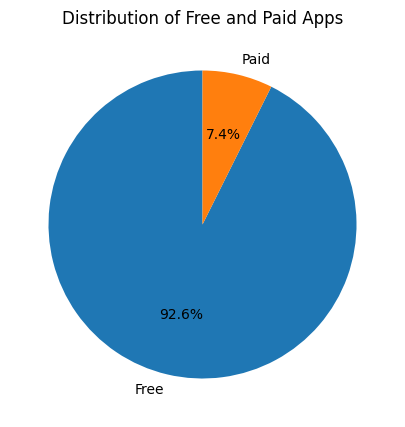

In [19]:
### Paid vs Free App Distribution
type_counts = apps['Type'].value_counts()
plt.figure(figsize=(6, 5))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Free and Paid Apps')
plt.show()

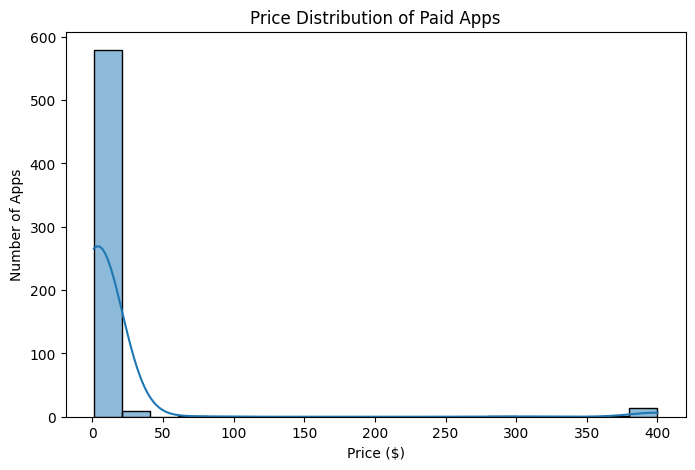

In [20]:
### Price Distribution of Paid Apps
paid_apps = apps[apps['Type'] == 'Paid']
plt.figure(figsize=(8, 5))
sns.histplot(paid_apps['Price'], bins=20, kde=True)
plt.title('Price Distribution of Paid Apps')
plt.xlabel('Price ($)')
plt.ylabel('Number of Apps')
plt.show()

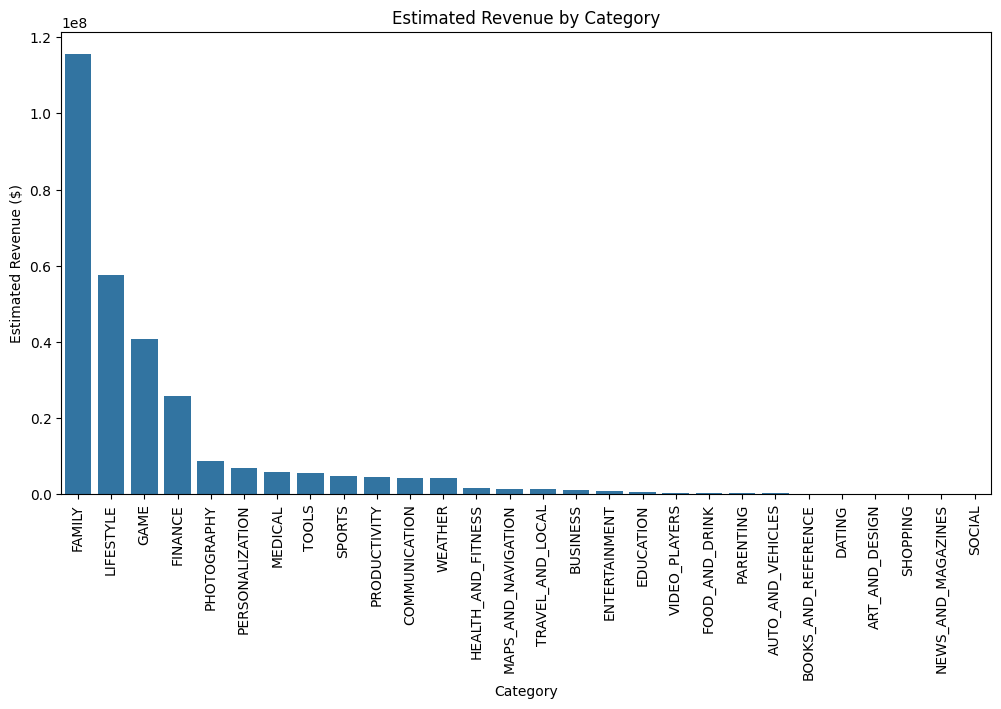

In [21]:
### Estimated Revenue by Category
paid_apps = apps[apps['Type'] == 'Paid'].copy()
paid_apps['Revenue'] = paid_apps['Price'] * paid_apps['Installs']
category_revenue = paid_apps.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=category_revenue.index, y=category_revenue.values)
plt.xticks(rotation=90)
plt.title('Estimated Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Estimated Revenue ($)')
plt.show()

In [23]:
!pip install textblob
from textblob import TextBlob

In [24]:
### TextBlob Sentiment Classification
def get_sentiment(review):
    polarity = TextBlob(review).sentiment.polarity
    if polarity > 0:
      return 'Positive'
    elif polarity < 0:
      return 'Negative'
    else:
      return 'Neutral'
reviews['TextBlob_Sentiment'] = reviews['Translated_Review'].apply(get_sentiment)
reviews['TextBlob_Sentiment'].value_counts()

,count
TextBlob_Sentiment,
Positive,19014
Negative,6322
Neutral,4356


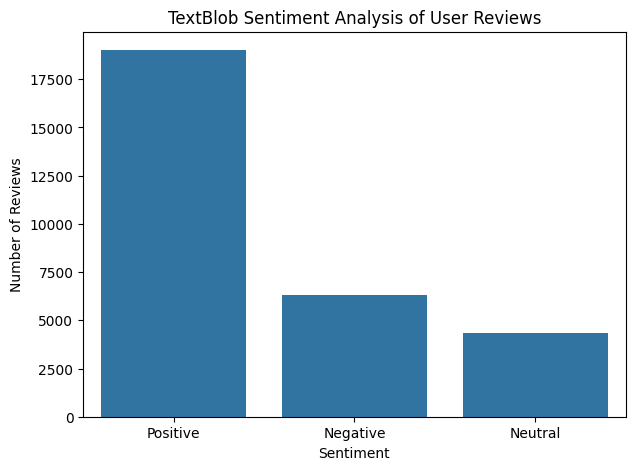

In [25]:
### TextBlob Sentiment Analysis visualization
sentiment_counts = reviews['TextBlob_Sentiment'].value_counts()
plt.figure(figsize=(7, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)
plt.title('TextBlob Sentiment Analysis of User Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [27]:
### Categories with Most Positive and Negative Sentiment
merged_data = pd.merge(apps[['App', 'Category']], reviews, on='App')
category_sentiment = merged_data.groupby(
    ['Category', 'TextBlob_Sentiment']
).size().unstack(fill_value=0)
print("Top 5 Categories with Positive Reviews:")
print(category_sentiment['Positive'].sort_values(ascending=False).head())
print("\nTop 5 Categories with Negative Reviews:")
print(category_sentiment['Negative'].sort_values(ascending=False).head())

Top 5 Categories with Positive Reviews:
Category
GAME                  2275
FAMILY                1584
HEALTH_AND_FITNESS    1262
TOOLS                  842
FINANCE                841
Name: Positive, dtype: int64

Top 5 Categories with Negative Reviews:
Category
GAME                1406
FAMILY               691
FINANCE              300
SPORTS               284
TRAVEL_AND_LOCAL     267
Name: Negative, dtype: int64


In [28]:
!pip install plotly

In [29]:
### Interactive App Category Distribution
import plotly.express as px
fig = px.bar(
    apps['Category'].value_counts().reset_index(),
    x='Category',
    y='count',
    title='Number of Apps in Each Category',
    labels={'count': 'Number of Apps', 'Category': 'App Category'}
)
fig.update_layout(xaxis_tickangle=-45)
fig.show()

Conclusion: 3 Key Insights
1. App Category: Family has the highest number of apps, followed by Game and Tools. Developers should check the competition and demand before choosing a category.

2. App Ratings: Most apps have ratings between 4.0 and 4.7. This shows that users prefer good-quality apps, so developers should focus on improving app performance and user experience.

3. App Pricing: Around 92.6% of apps are free and only 7.4% are paid. So, developers can start with a free app and offer some extra features as paid options.